# Run sorters and analyze them

Now that we've explored our data and have cleaned/preprocessed it, it's finally time to sort!

Let's read in our preprocessed recording

In [1]:
from pathlib import Path

import spikeinterface.full as si

si.set_global_job_kwargs(n_jobs=2)

In [2]:
# Modify this to where you downloaded your datasets

# Modify this to where you downloaded your datasets
home = Path.home()
base_data_folder = Path(home / "school_2026/data/")
results_folder = Path(home / "school_2026/results/")
preprocessed_path = results_folder / Path('preprocessed')
preprocessed_recording = si.load(preprocessed_path)

In [3]:
%matplotlib widget
si.plot_traces(preprocessed_recording, backend="ipywidgets")

AppLayout(children=(TimeSlider(children=(Dropdown(description='Segment', options=(0,), value=0), Button(icon='…

### Check installation

We can now run spike sorting on the above recording. We will use different spike sorters for this demonstration, to show how easy `SpikeInterface` makes it easy to interchengably run different sorters :)

Let's first check the available and installed sorters in `SpikeInterface`.
We will sort the bandpass cached filtered recording the `recording_saved` object.

In [4]:
si.available_sorters()

['combinato',
 'dartsort',
 'hdsort',
 'herdingspikes',
 'ironclust',
 'kilosort',
 'kilosort2',
 'kilosort2_5',
 'kilosort3',
 'kilosort4',
 'lupin',
 'mountainsort4',
 'mountainsort5',
 'pykilosort',
 'rtsort',
 'simple',
 'spykingcircus',
 'spykingcircus2',
 'tridesclous',
 'tridesclous2',
 'waveclus',
 'waveclus_snippets',
 'yass']

In [5]:
si.installed_sorters()

['lupin', 'simple', 'spykingcircus2', 'tridesclous2']

The `spikeinterface.sortingcomponents` module includes functions that can be used to create custom spike sorting pipelines built-in in `SpikeInterface`. We have used it to create some sorters

* `lupin` (developed by the SpikeInterface team - primarily Sam Garcia and Pierre Yger)
* `tridesclous2` (developed by Samuel Garcia)
* `spykingcircus2` (developed by Pierre Yger)
* `simple` which is only for demo and teaching

Let's run one now. Every sorter comes with a dizzying array of parameters, which we can check using `get_default_sorter_params`

In [6]:
si.get_default_sorter_params('lupin')

{'apply_preprocessing': True,
 'preprocessing_dict': None,
 'apply_motion_correction': False,
 'motion_correction_preset': 'dredge_fast',
 'clustering_ms_before': 0.3,
 'clustering_ms_after': 1.3,
 'whitening_radius_um': 100.0,
 'detection_radius_um': 50.0,
 'features_radius_um': 120.0,
 'split_radius_um': 60.0,
 'template_radius_um': 100.0,
 'merge_similarity_lag_ms': 0.5,
 'freq_min': 150.0,
 'freq_max': 7000.0,
 'cache_preprocessing_mode': 'auto',
 'peak_sign': 'neg',
 'detect_threshold': 5.0,
 'n_peaks_per_channel': 5000,
 'n_svd_components_per_channel': 5,
 'n_pca_features': 4,
 'clustering_recursive_depth': 3,
 'ms_before': 1.0,
 'ms_after': 2.5,
 'template_sparsify_threshold': 1.0,
 'template_min_snr_ptp': 4.0,
 'template_max_jitter_ms': 0.2,
 'template_matching_engine': 'wobble',
 'min_firing_rate': 0.1,
 'gather_mode': 'memory',
 'job_kwargs': {},
 'seed': None,
 'save_array': True,
 'debug': False}

### Run sorter installed locally

This run a sorter which is installed in the current python environements.

In [7]:
sorter_params = {'apply_motion_correction': False, 'apply_preprocessing': True}

In [8]:
sorting_lupin = si.run_sorter(
    sorter_name='lupin', 
    recording=preprocessed_recording,
    folder=results_folder / 'sorting_lupin',
    verbose=True,
    remove_existing_folder=True,
    **sorter_params
)


                            .::----::..
                 ..:-+#%*+#%@@@@@@@+..:+#+.
                .+@%%@@@@@@@@@@@@@@#:  .=@=
                -@@@@@@@@@@@@@@@@@@%-. .=@*
                .@@@@@@@@@@@@@@@@@@@*. .-%#
                 %@@@@@@@@@@@@@@@@@@*.  :#%
                 =%%@@@@@@@@@@@@@@%%+:  .+@.
                 -%#@@@@@@@@@@@@@@%*==  .-@.
                 :#%@@@@@@@@@@@@@@%#+#  .=@.
                 .+%@@@@@@@@@@@@@@@%#@. .+@.
                 .+*#@@@@@@@@@@@@@@@%@. .+@:
                 .=%+@@@@@@@@@@@@@@@@*.  =%-.
                  :#%##@@@@@@@@@@@@%%-.  :%+.
               ..:=**%@@@@@@@@@@@@@@@:.  .%%......
             .+#@%%%@**@%@@@@@@@@@@@*....=%@%@@@@@%=..
            .*@@@@@@@@@@@=#@@@@@@@@@@*=:.:.#@@@@@@%%-.
           .-%%@@@@@@@@@@@@@#+%@+-::-+=:=::+@@@@@@##-.
           .:%@@@@@@@@@@@@@@@@@%+%##*%%%**%@@@@@@##+.
            .+@@@@@@@@@@@@@@@@#***++***@@@@@@@@%%%=.
             .:*@@@@@@@@%=-.....   ....:-*%%%%%+-.
                 ..:-:..
                       

write_memory (workers: 2 processes fork):   0%|          | 0/90 [00:00<?, ?it/s]

noise_level (workers: 2 processes fork):   0%|          | 0/20 [00:00<?, ?it/s]

get protoype waveforms (workers: 2 processes fork):   0%|          | 0/90 [00:00<?, ?it/s]

detect peaks (matched_filtering) (workers: 2 processes fork):   0%|          | 0/90 [00:00<?, ?it/s]

detect_peaks(): 73420 peaks found
select_peaks(): 73420 peaks kept for clustering


... (6 outputs left out)

/run/media/pierre/Secondary/pierre/softwares/school_neuralnet_paris_2026/.venv/lib/python3.13/site-packages/spikeinterface/core/template_tools.py:397: UserWarning: get_template_peak_shift_on_main_channel() with Templates should provide a peak_sign
  warnings.warn("get_template_peak_shift_on_main_channel() with Templates should provide a peak_sign")


find spikes (wobble) (workers: 2 processes fork):   0%|          | 0/90 [00:00<?, ?it/s]

lupin run time 70.05s


/run/media/pierre/Secondary/pierre/softwares/school_neuralnet_paris_2026/.venv/lib/python3.13/site-packages/spikeinterface/core/core_tools.py:968: UserWarning: The extractor is not serializable to file. The provenance will not be saved.
  warnings.warn("The extractor is not serializable to file. The provenance will not be saved.")


In [12]:
sorting_lupin

NumpyFolder (NumpyFolderSorting): 116 units - 1 segments - 20.0kHz

## external sorter : kilosort4

SpikeInterface also supports external sorters such as `kilosort`, `dartsort` and `mountainsort`. But we leave it up to the user to install these. Luckily, there should be simple install instructions if you try and fail to run the sorter

In [13]:
si.get_default_sorter_params('kilosort4')

{'pool_engine': 'process',
 'n_jobs': 2,
 'chunk_duration': '1s',
 'progress_bar': True,
 'mp_context': None,
 'max_threads_per_worker': 1}

In [17]:
sorter_params = {
    "do_correction": False,
    "use_binary_file": False,
}

sorting_kilosort = si.run_sorter(
    sorter_name='kilosort4', 
    recording=preprocessed_recording,
    folder=results_folder / 'sorting_kilosort',
    verbose=True,
    remove_existing_folder=True,
    **sorter_params
)

kilosort.io : ========================================
kilosort.io : Loading recording with SpikeInterface...
kilosort.io : number of samples: 1800000
kilosort.io : number of channels: 60
kilosort.io : numbef of segments: 1
kilosort.io : sampling rate: 20000.0
kilosort.io : dtype: int16
kilosort.io : ========================================
kilosort.run_kilosort:  
kilosort.run_kilosort: Computing preprocessing variables.
kilosort.run_kilosort: ----------------------------------------
kilosort.run_kilosort: N samples: 1800000
kilosort.run_kilosort: N seconds: 90.0
kilosort.run_kilosort: N batches: 30
kilosort.run_kilosort: Preprocessing filters computed in 0.37s; total 0.37s
kilosort.run_kilosort:  
kilosort.run_kilosort: Resource usage after preprocessing
kilosort.run_kilosort: ********************************************************
kilosort.run_kilosort: CPU usage:     2.00 %
kilosort.run_kilosort: Mem used:     11.50 %     |      21.12 GB
kilosort.run_kilosort: Mem avail:    162.16

Skipping drift correction.


kilosort.spikedetect: Number of universal templates: 246
kilosort.spikedetect: Detecting spikes...
100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 30/30 [00:03<00:00,  9.15it/s]
kilosort.run_kilosort: 39808 spikes extracted in 3.93s; total 4.35s
kilosort.run_kilosort:  
kilosort.run_kilosort: Resource usage after spike detect (univ)
kilosort.run_kilosort: ********************************************************
kilosort.run_kilosort: CPU usage:     0.00 %
kilosort.run_kilosort: Mem used:     11.70 %     |      21.42 GB
kilosort.run_kilosort: Mem avail:    161.86 / 183.28 GB
kilosort.run_kilosort: ------------------------------------------------------
kilosort.run_kilosort: GPU usage:    `conda install pynvml` for GPU usage
kilosort.run_kilosort: GPU memory:   16.35 %     |      2.54   /    15.55 GB
kilosort.run_kilosort: Allocated:     0.00 %     |      0.00   /    15.55

kilosort4 run time 17.79s


In [21]:
si.get_default_sorter_params('dartsort')

/run/media/pierre/Secondary/pierre/softwares/school_neuralnet_paris_2026/.venv/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/run/media/pierre/Secondary/pierre/softwares/school_neuralnet_paris_2026/.venv/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/run/media/pierre/Secondary/pierre/softwares/school_neuralnet_paris_2026/.venv/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


{'do_motion_estimation': True,
 'already_preprocessed': 'assume_yes_if_float',
 'preprocessing': 'ibllikecmr',
 'preprocessing_dtype': 'float32',
 'subsampling_spikes_per_channel': 5000,
 'subsampling_presence': 0.025,
 'subsampling_max_seconds': inf,
 'matching_iterations': 1,
 'dredge_only': False,
 'seed': 0,
 'n_jobs_cpu': 0,
 'n_jobs_gpu': 0,
 'motion_n_jobs_gpu': 2,
 'n_jobs_small': -2,
 'n_jobs_small_gpu': 4,
 'device': None,
 'executor': 'threading_unless_multigpu',
 'chunk_length_samples': 30000,
 'work_in_tmpdir': False,
 'copy_recording_to_tmpdir': 'if_preprocessing',
 'workdir_copier': 'shutil',
 'workdir_follow_symlinks': False,
 'tmpdir_parent': None,
 'save_intermediates': False,
 'save_final_features': True,
 'ms_before': 1.4,
 'ms_after': 2.6333333333333333,
 'alignment_ms': 1.5,
 'deduplication_ms': 0.25,
 'peak_sign': 'both',
 'voltage_threshold': 3.0,
 'matching_threshold': 6.0,
 'initial_threshold': 9.0,
 'motion_voltage_threshold': 4.0,
 'temporal_pca_rank': 8,
 '

In [22]:
sorter_params = {
    "do_motion_estimation": False,
}

sorting_dartsort = si.run_sorter(
    sorter_name='dartsort', 
    recording=preprocessed_recording,
    folder=results_folder / 'sorting_dartsort',
    verbose=True,
    remove_existing_folder=True,
    **sorter_params
)

detect_bad_channels (workers: 2 processes fork):   0%|          | 0/100 [00:00<?, ?it/s]

noise_level (workers: 2 processes fork):   0%|          | 0/100 [00:00<?, ?it/s]

/run/media/pierre/Secondary/pierre/softwares/school_neuralnet_paris_2026/.venv/lib/python3.13/site-packages/dartsort/main.py:156: RuntimeWarning: Your (preprocessed) recording is not saved on disk in time-major format, so reading data could be slow. You could set the config flag copy_recording_to_tmpdir to keep it in a scratch folder while dartsort runs, or cache it long-term with its .save() method.
  check_recording(recording, copy_flag=copy_rec_flag)


Load initial denoiser fit data:cuda 1.5s/it [spk/it=%%%]:   0%|          | 0/60 [00:00<?, ?it/s]

Epochs:   0%|          | 0/100 [00:00<?, ?epoch/s]

Load examples for denoiser fitting:cuda 1.5s/it [spk/it=%%%]:   0%|          | 0/60 [00:00<?, ?it/s]

... (36 outputs left out)

Raw templates:cuda 1.5s/it [spk/it=%%%]:   0%|          | 0/60 [00:00<?, ?it/s]

Templates:cuda 1.5s/it [spk/it=%%%]:   0%|          | 0/60 [00:00<?, ?it/s]

dartsort run time 680.48s


/run/media/pierre/Secondary/pierre/softwares/school_neuralnet_paris_2026/.venv/lib/python3.13/site-packages/spikeinterface/core/core_tools.py:968: UserWarning: The extractor is not serializable to file. The provenance will not be saved.
  warnings.warn("The extractor is not serializable to file. The provenance will not be saved.")


# The `sorting` object 

In [54]:
sorting_lupin

NumpyFolder (NumpyFolderSorting): 116 units - 1 segments - 20.0kHz

As we'll see, the main output of a `SpikeInterface` pipeline is the `SortingAnalyzer` object, which you'll be able to do _lots_ of fun stuff with. But there are some simple things you can do with the `Sorting` object.

## Get spike trains

In [24]:
# spike times in frame

unit_id = sorting_lupin.unit_ids[0]

spike_times = sorting_lupin.get_unit_spike_train(unit_id)
print(spike_times)

# spike times in seconds
spike_times = sorting_lupin.get_unit_spike_train(unit_id, return_times=True)
print(spike_times)


[   3240    7409   11633   17501   20288   21789   22315   26232   27997
   28149   30579   30858   32950   35762   36252   36395   36526   37629
   39352   39482   40718   41819   47159   47739   48047   49358   50075
   53904   64032   73435   73621   74491   80330   81019   88007   93962
   97677  105527  105927  106031  106230  106474  107902  108211  108275
  109142  109457  109762  110710  110738  112572  113246  124417  126539
  132483  133652  135515  139801  149987  161867  166854  167799  178971
  180114  182207  188379  194559  197925  206906  207701  208138  208439
  266853  268856  270512  273347  275459  288235  288385  295053  298241
  325260  335745  335892  336376  342590  349725  366507  367382  369384
  385683  389255  392914  393255  394565  394890  395432  396511  397433
  398228  403573  404032  404535  404877  415612  416956  435954  436701
  437555  443763  458043  461437  464537  466912  469803  473611  477994
  481544  481828  483042  484108  485683  490537  4

In [25]:
# time slice
sorting_lupin.frame_slice(0, 30_000)

FrameSliceSorting: 116 units - 1 segments - 20.0kHz

## Plot

In [26]:
si.plot_rasters(sorting_lupin, unit_ids=sorting_lupin.unit_ids[:60], time_range=(0, 5), backend='ipywidgets')

AppLayout(children=(VBox(children=(UnitSelector(children=(Label(value='Units', layout=Layout(justify_content='…

## Compare sorter outputs

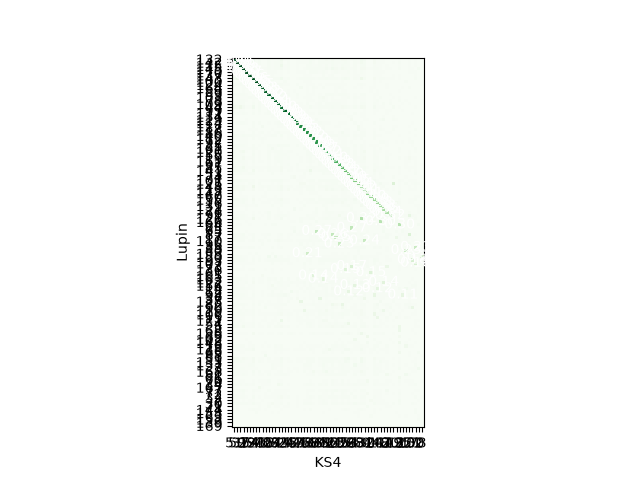

In [44]:
comp = si.compare_two_sorters(sorting_lupin, sorting_kilosort, 'Lupin', 'KS4')
w = si.plot_agreement_matrix(comp)
import pylab as plt
plt.show()

# Analyze Sorting

We now have a sorter and recording. Great! Now we can get on to the fun stuff: what shape are our unit templates? Which units are correlated with each other? Where on the probe are the units? This require computing extra information. In `SpikeInterface` we do this by creating an object called a `SortingAnalyzer`. 

A `SortingAnalyzer` combines a recording with a sorting in a unified way, no matter which sorter or recording format you used. Once you have an analyzer, you can compute postprocessing _extensions_ (like spike locations, waveforms, template metrics, ...) in exactly the same way for every sorter. They can also be used to keep track of curation, merging and splitting, and more.

This unified framework has several benefits. The main one is that the analyzer defines a sorter-agnostic format for post-sorting analysis. Hence:
- You can compare sorters on a level playing field (i.e. all the extensions are computed in the same way, for all sorters)
- Your postprocessing pipeline can be identical, whether using mountainsort to sort tetrode data or kilosort to sort NeuroPixel data, creating a unified pipeline in your lab.
- External tools have a simple starting point to work from. This should make tooling in the community easier, and there are already several examples of this:
  - NeuronConv contains a `SortingAnalyzerToNWB` function
  - spikeinterface-gui, sortingview and UnitMatch can take an analyzer as their initial input.
  - UnitRefine
  - BombCell
  - IBL viewer tools

Hopefully you're now convinced that creating a `SortingAnalyzer` will make your life easier, and smooth the path to using new tools in your analysis pipeline. So, let's make one.

When you make the analyzer, you can either make in _in memory_ or _in folder_. 

In [45]:
analyzer_in_memory = si.create_sorting_analyzer(
    sorting=sorting_lupin,
    recording=preprocessed_recording, 
)

analyzer_in_folder = si.create_sorting_analyzer(
    sorting=sorting_lupin, 
    recording=preprocessed_recording, 
    folder=results_folder / f"analyzer_lupin",
    overwrite=True,
    format="binary_folder",
)

/run/media/pierre/Secondary/pierre/softwares/school_neuralnet_paris_2026/.venv/lib/python3.13/site-packages/spikeinterface/core/basesorting.py:646: UserWarning: The recording registered to this sorting object will not be saved to disk. Reloading the sorting later will not include the recording
  warnings.warn(


When in memory, the analyzer is stored in RAM. This makes computation faster, but will use more RAM. You can save your `analyzer_in_memory` to a folder at any point using `analyzer_in_memory.save_as` (more info in [Postprocessing docs](https://spikeinterface.readthedocs.io/en/stable/modules/postprocessing.html)). For this demo, we'll use a folder based analyzer. Go take a look in the folder. You'll see that it contains recording information, sorting information and more!

# Extensions

Each thing-you'd-like-to-compute is stored as an Extention of the analyzer. Let's compute the templates: the averaged waveforms from all (or a large random sample of) individual spikes.

In [46]:
analyzer_in_folder.compute("templates")

AssertionError: Extension templates requires random_spikes|waveforms to be computed first

Oh no - an error! This is due to the fact that extensions depend on each other. For example, you can't compute template similarity (how similar unit templates are to one another) without computing templates. The full dependency graph can be seen here:

![image](images/parent_child.svg)

So, when we compute extensions we need to know which _other_ extensions we need to compute beforehand... Let's compute a few. You can either compute one at a time, or give the `analyzer` a big dictionary of extensions (recommended! It will do some smart stuff to save some computation time):

In [47]:
# just one
analyzer_in_folder.compute("random_spikes", max_spikes_per_unit=1000)

# or lots: here we also specify some kwargs
analyzer_in_folder.compute({
    "templates": {},
    "waveforms": {},
    "correlograms": {},
    "noise_levels": {'method': 'std'},
    "spike_amplitudes": {},
    "spike_locations": {},
    "template_metrics": {'include_multi_channel_metrics': True},
    "unit_locations": {},
    "template_similarity": {'method': 'l1'},
    "quality_metrics": {},
})


compute_waveforms (workers: 2 processes fork):   0%|          | 0/90 [00:00<?, ?it/s]

/run/media/pierre/Secondary/pierre/softwares/school_neuralnet_paris_2026/.venv/lib/python3.13/site-packages/spikeinterface/metrics/template/template_metrics.py:302: UserWarning: With less than 10 channels, multi-channel metrics might not be reliable.
  warnings.warn(


Compute : spike_amplitudes + spike_locations (workers: 2 processes fork):   0%|          | 0/90 [00:00<?, ?it/…

/run/media/pierre/Secondary/pierre/softwares/school_neuralnet_paris_2026/.venv/lib/python3.13/site-packages/spikeinterface/core/analyzer_extension_core.py:1207: UserWarning: The following metrics will not be computed due to missing dependencies: ['nearest_neighbor', 'd_prime', 'mahalanobis', 'silhouette']
  warnings.warn(
/run/media/pierre/Secondary/pierre/softwares/school_neuralnet_paris_2026/.venv/lib/python3.13/site-packages/numpy/_core/_methods.py:219: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/run/media/pierre/Secondary/pierre/softwares/school_neuralnet_paris_2026/.venv/lib/python3.13/site-packages/numpy/_core/_methods.py:178: RuntimeWarning: invalid value encountered in divide
  arrmean = um.true_divide(arrmean, div, out=arrmean,
/run/media/pierre/Secondary/pierre/softwares/school_neuralnet_paris_2026/.venv/lib/python3.13/site-packages/numpy/_core/_methods.py:211: RuntimeWarning: invalid value encountered in divi

In [48]:
analyzer_in_folder

SortingAnalyzer: 60 channels - 116 units - 1 segments - binary_folder - sparse - has recording
Loaded 11 extensions: random_spikes, waveforms, templates, correlograms, noise_levels, template_metrics, unit_locations, template_similarity, spike_amplitudes, spike_locations, quality_metrics

To see which extensions are available to compute, use `analyzer_in_folder.get_computable_extensions()`. A good way to see which arguments an extension accepts, you can use e.g. `analyzer_in_folder.get_default_extension_params('template_metrics')`

Now take another look in your analyzer folder. You'll find lots of new folders containing your extensions! You can load this data directly, but `SpikeInterface` contains a lot of handy loader functions. The notation is always `analyzer.get_extension("extension_name").get_data()`. Let's look at the quality metrics. These are measures of how _good_ a unit is (more details: https://spikeinterface.readthedocs.io/en/latest/modules/qualitymetrics.html) Note that which quality metrics are computed depends on which other extensions you've computed.

In [49]:
quality_metrics = analyzer_in_folder.get_extension("quality_metrics").get_data()
quality_metrics

,num_spikes,firing_rate,presence_ratio,snr,isi_violations_ratio,isi_violations_count,rp_contamination,rp_violations,sliding_rp_violation,sync_spike_2,...,amplitude_cv_median,amplitude_cv_range,amplitude_cutoff,noise_cutoff,noise_ratio,amplitude_median,drift_ptp,drift_std,drift_mad,sd_ratio
2,573,6.366667,1.0,3.746411,0.456859,5,0.578510,3,NaN,0.092496,...,0.319266,0.082174,0.0,-0.025358,0.072581,-78.779999,NaN,NaN,NaN,1.194592
3,787,8.744444,1.0,3.921289,0.581237,12,0.642027,6,NaN,0.064803,...,0.372898,0.255811,0.0,0.088389,0.076136,-100.230003,NaN,NaN,NaN,1.395290
5,2963,32.922222,1.0,4.856046,0.085428,25,0.091304,17,0.115,0.066824,...,0.252347,0.123190,0.0,-0.007854,0.113505,-99.449997,NaN,NaN,NaN,1.238414
9,1264,14.044444,1.0,5.583245,0.000000,0,0.000000,0,0.040,0.063291,...,0.208937,0.109409,0.0,-0.398368,0.067736,-112.904999,NaN,NaN,NaN,1.191478
13,654,7.266667,1.0,4.096297,0.561120,8,1.000000,7,NaN,0.081040,...,0.262590,0.132228,0.0,0.057085,0.128968,-76.830002,NaN,NaN,NaN,1.130388
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
166,161,1.788889,1.0,4.694534,0.000000,0,0.000000,0,NaN,0.049689,...,NaN,NaN,NaN,-0.213078,0.047022,-115.440002,NaN,NaN,NaN,1.437819
167,25,0.277778,1.0,6.895965,0.000000,0,0.000000,0,NaN,0.040000,...,NaN,NaN,NaN,-0.179180,0.038462,-171.210007,NaN,NaN,NaN,1.445964
168,655,7.277778,1.0,4.482958,0.629334,9,0.598891,4,NaN,0.108397,...,0.300463,0.121553,0.0,0.319981,0.131696,-109.394997,NaN,NaN,NaN,1.383511
169,12,0.133333,1.0,7.293048,0.000000,0,0.000000,0,NaN,0.166667,...,NaN,NaN,NaN,4.242641,0.500000,-181.837494,NaN,NaN,NaN,0.712033


This is a `pandas` dataframe with information about each unit. Nice.

We can get the "raw" extension data from any other extensions too

In [50]:
template_similarity_data = analyzer_in_folder.get_extension("template_similarity").get_data()
template_similarity_data

array([[1.        , 0.5523034 , 0.39142686, ..., 0.        , 0.        ,
        0.        ],
       [0.5523034 , 1.        , 0.60905945, ..., 0.        , 0.        ,
        0.        ],
       [0.39142686, 0.60905945, 1.        , ..., 0.        , 0.        ,
        0.        ],
       ...,
       [0.        , 0.        , 0.        , ..., 1.        , 0.4309932 ,
        0.11382639],
       [0.        , 0.        , 0.        , ..., 0.4309932 , 1.        ,
        0.09356421],
       [0.        , 0.        , 0.        , ..., 0.11382639, 0.09356421,
        1.        ]], shape=(116, 116), dtype=float32)

`SpikeInterface` also supports lots of plotting functions that are related to extensions (see more: https://spikeinterface.readthedocs.io/en/latest/modules/widgets.html#available-plotting-functions). Let's plot the spike locations, then a summary plot.

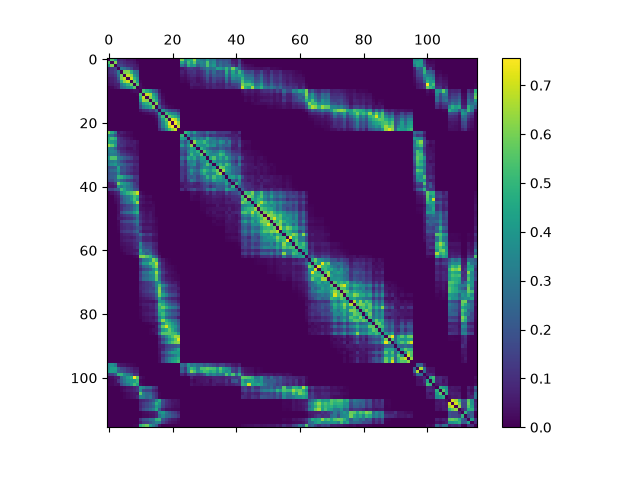

In [51]:
si.plot_template_similarity(analyzer_in_folder)

In [42]:
%matplotlib widget
si.plot_amplitudes(analyzer_in_folder, backend="ipywidgets")

AppLayout(children=(VBox(children=(UnitSelector(children=(Label(value='Units', layout=Layout(justify_content='…

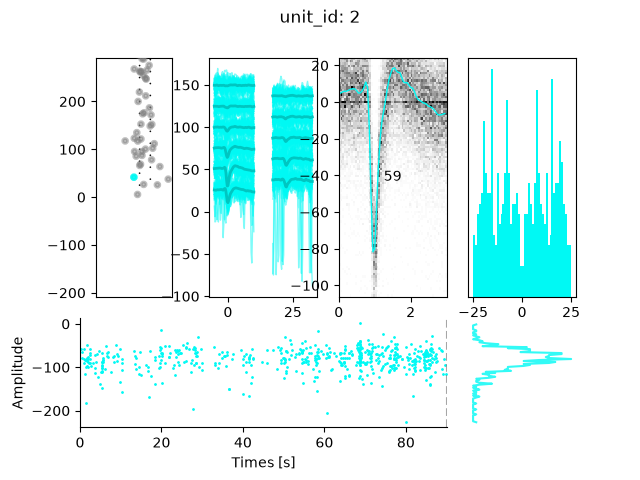

In [52]:
si.plot_unit_summary(analyzer_in_folder, unit_id=unit_id)
plt.show()

In [ ]:
si.plot_quality_metrics(analyzer_in_folder, backend="ipywidgets")

# Export

We are trying to improve `export` options for the `SortingAnalyzer` so that SpikeInterface works with other tools. For example, we recently introduced the ability to `export_to_pynapple` (https://pynapple.org/)

In [53]:
spikes = si.to_pynapple_tsgroup(analyzer_in_folder)
spikes

Index    rate      x       y       z      num_spikes    firing_rate    presence_ratio    ...
-------  --------  ------  ------  -----  ------------  -------------  ----------------  -----
2        6.36678   -11.86  41.69   1.0    573           6.37           1.0               ...
3        8.7446    42.48   63.9    1.0    787           8.74           1.0               ...
5        32.92279  25.13   78.07   12.71  2963          32.92          1.0               ...
9        14.04469  22.13   148.64  1.0    1264          14.04          1.0               ...
13       7.26679   20.57   186.61  17.45  654           7.27           1.0               ...
14       9.36683   -3.06   200.02  16.24  843           9.37           1.0               ...
15       4.92231   12.92   211.75  15.24  443           4.92           1.0               ...
...      ...       ...     ...     ...    ...           ...            ...               ...
164      3.66673   -1.03   543.12  1.0    330           3.67        

If you want to know more about Pynapple, and use it to study the head direction cells in this dataset, there's a whole chapter about it on the [Open Software Summer School course](https://neuroinformatics.dev/course_ephys_osss/pynapple.html).

Another export option is `export_report`. This creates a cute little report about all your units:

In [37]:
si.export_report(analyzer_in_folder, output_folder=results_folder / "lupin_report")